### Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import joblib

from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


### Load the final trained model

In [2]:
model_files = list(
    Path("../models/final").rglob("random_forest_final.joblib")
)

if not model_files:
    raise FileNotFoundError("Final Random Forest model not found.")

final_model_path = model_files[0]

final_model = joblib.load(final_model_path)

print("Final model loaded successfully.")
print("Model type:", type(final_model).__name__)

Final model loaded successfully.
Model type: Pipeline


In [3]:
# Extract trained Random Forest classifier
rf_classifier = final_model.named_steps["classifier"]

# Extract feature names after preprocessing
feature_names = final_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Extract importance scores
importance_scores = rf_classifier.feature_importances_

# Create feature importance dataframe
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance_df.head(20).round(6))

,Feature,Importance
0,numerical__signup_tenure_days,0.294306
1,numerical__organization_tenure_days,0.180498
2,numerical__subscription_tenure_days,0.100127
3,numerical__unique_event_types,0.031331
4,numerical__unique_platforms,0.029200
5,numerical__unique_device_types,0.027383
6,numerical__total_event_count,0.025379
7,numerical__api_avg_response_time_ms,0.018715
8,numerical__unique_sessions,0.017651
9,numerical__active_event_days,0.017461


### Visualize the top 20 features

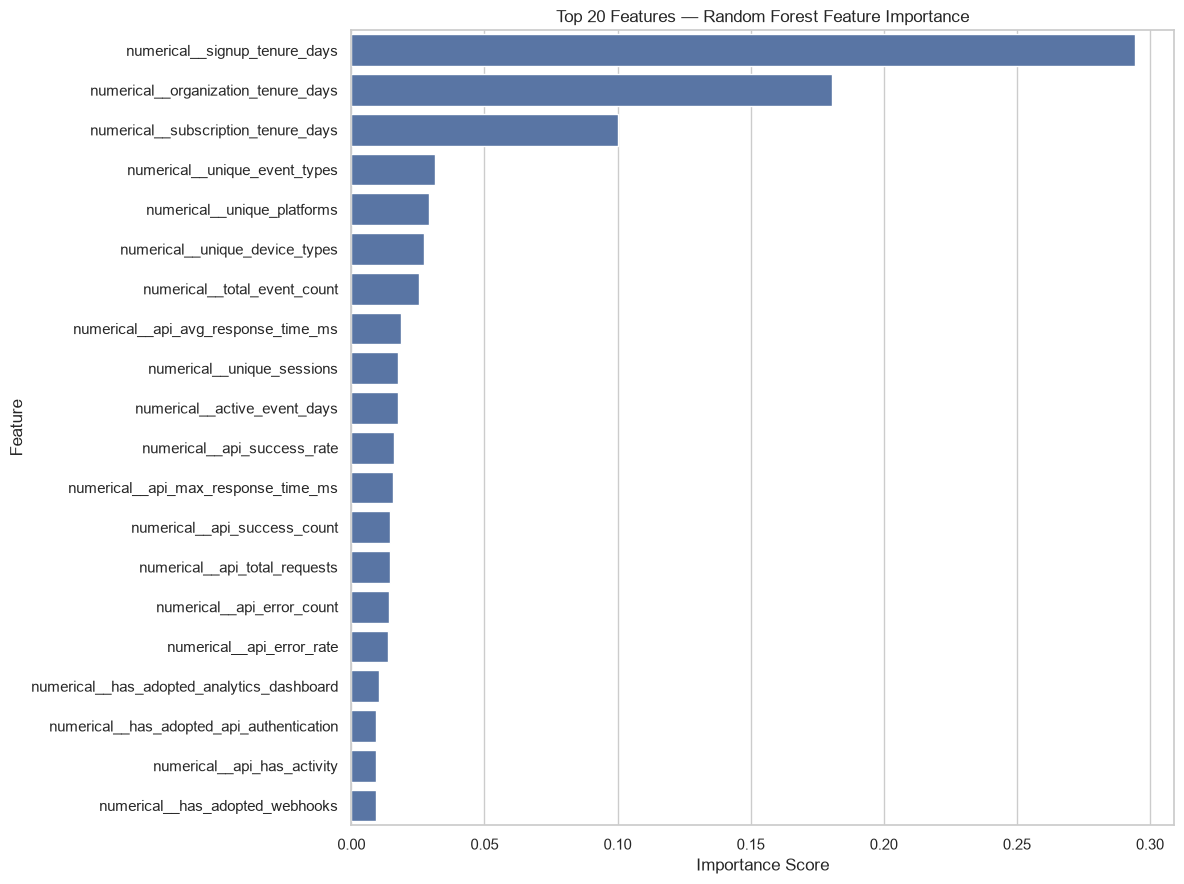

In [4]:
top_20_features = feature_importance_df.head(20).copy()

plt.figure(figsize=(12, 9))

sns.barplot(
    data=top_20_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Features — Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()

plt.show()

### Save Feature Importance Results

In [5]:
# Define output directory
output_dir = Path("../models/interpretation")
output_dir.mkdir(parents=True, exist_ok=True)

# Save feature importance results
importance_file = output_dir / "random_forest_feature_importance.csv"

feature_importance_df.to_csv(
    importance_file,
    index=False
)

print("Feature importance results saved successfully.")
print("File:", importance_file.resolve())
print("Total features saved:", len(feature_importance_df))

Feature importance results saved successfully.
File: C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\notebooks\models\interpretation\random_forest_feature_importance.csv
Total features saved: 84


### Prepare for Permutation Importance

In [6]:
required_variables = ["X_fit", "y_fit", "X_val", "y_val"]

for variable in required_variables:
    print(
        f"{variable}:",
        "Available" if variable in globals() else "Not available"
    )

X_fit: Not available
y_fit: Not available
X_val: Not available
y_val: Not available


### Locate the processed training dataset

In [7]:
from pathlib import Path

project_root = Path.cwd()

processed_dir = project_root.parent / "data" / "processed"

print("Notebook directory:", project_root)
print("Processed data directory:", processed_dir.resolve())

csv_files = list(processed_dir.rglob("*.csv"))

for file in csv_files:
    print(file.name, "->", file)

Notebook directory: C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\notebooks\02_machine_learning
Processed data directory: C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\notebooks\data\processed
api_monitoring_adoption_summary.csv -> C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\notebooks\data\processed\api_monitoring_adoption_summary.csv
api_usage_features.csv -> C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\notebooks\data\processed\api_usage_features.csv
baseline_model_comparison.csv -> C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\notebooks\data\processed\baseline_model_comparison.csv
categorical_value_report.csv -> C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\notebooks\data\processed\categorical_value_report.csv
data_type_report.csv -> C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\notebooks\data\processed\data_type_report.csv
date_type_re

### Load training data and cohort metadata

In [8]:
# Load original training features and target
X_train = pd.read_csv(processed_dir / "X_train.csv")
y_train = pd.read_csv(processed_dir / "y_train.csv")

# Load training cohort metadata
train_metadata = pd.read_csv(
    processed_dir / "train_cohort_metadata.csv"
)

# Display dataset information
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("Metadata shape:", train_metadata.shape)

print("\nTarget columns:")
print(y_train.columns.tolist())

print("\nMetadata columns:")
print(train_metadata.columns.tolist())

print("\nMetadata preview:")
display(train_metadata.head())

X_train shape: (70577, 50)
y_train shape: (70577, 1)
Metadata shape: (70577, 3)

Target columns:
['feature_adopted']

Metadata columns:
['user_id', 'index_date', 'feature_adopted']

Metadata preview:


,user_id,index_date,feature_adopted
0,1398,2024-03-01,0
1,9381,2024-03-01,0
2,2037,2024-03-01,0
3,9249,2024-03-01,0
4,5559,2024-03-01,0


### Recreate the chronological validation split

In [9]:
# Convert index_date to datetime
train_metadata["index_date"] = pd.to_datetime(
    train_metadata["index_date"]
)

# Identify unique cohort dates
cohort_dates = sorted(
    train_metadata["index_date"].unique()
)

print("Total cohort dates:", len(cohort_dates))
print("First cohort date:", cohort_dates[0])
print("Last cohort date:", cohort_dates[-1])

# Recreate the chronological split
fit_dates = cohort_dates[:19]
validation_dates = cohort_dates[19:]

# Create row masks
fit_mask = train_metadata["index_date"].isin(fit_dates)
validation_mask = train_metadata["index_date"].isin(validation_dates)

# Split features
X_fit = X_train.loc[fit_mask].copy()
X_val = X_train.loc[validation_mask].copy()

# Split target
y_fit = y_train.loc[fit_mask, "feature_adopted"].copy()
y_val = y_train.loc[validation_mask, "feature_adopted"].copy()

# Display split information
print("\nFit period:")
print(fit_dates[0], "to", fit_dates[-1])

print("\nValidation period:")
print(validation_dates[0], "to", validation_dates[-1])

print("\nDataset shapes:")
print("X_fit:", X_fit.shape)
print("y_fit:", y_fit.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nPositive cases:")
print("Fit positives:", y_fit.sum())
print("Validation positives:", y_val.sum())

print("\nValidation positive rate:", round(y_val.mean() * 100, 3), "%")

Total cohort dates: 24
First cohort date: 2024-03-01 00:00:00
Last cohort date: 2026-01-20 00:00:00

Fit period:
2024-03-01 00:00:00 to 2025-08-23 00:00:00

Validation period:
2025-09-22 00:00:00 to 2026-01-20 00:00:00

Dataset shapes:
X_fit: (41857, 50)
y_fit: (41857,)
X_val: (28720, 50)
y_val: (28720,)

Positive cases:
Fit positives: 1208
Validation positives: 412

Validation positive rate: 1.435 %


### Train the interpretation model

In [11]:
# Identify numerical features
numerical_features = X_fit.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical features
categorical_features = X_fit.select_dtypes(
    include=["object", "str", "category", "bool"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 43
Categorical features: 7


In [12]:
print("Interpretation model trained successfully.")
print("Training rows:", len(X_fit))
print("Validation rows:", len(X_val))

Interpretation model trained successfully.
Training rows: 41857
Validation rows: 28720


### Calculate Permutation Importance

In [13]:
# Calculate permutation importance on validation data
permutation_results = permutation_importance(
    interpretation_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

print("Permutation importance calculated successfully.")

Permutation importance calculated successfully.


### Create the permutation importance table

In [14]:
# Create permutation importance dataframe
permutation_importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance_Mean": permutation_results.importances_mean,
    "Importance_Std": permutation_results.importances_std
})

# Sort by mean importance
permutation_importance_df = permutation_importance_df.sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

# Display top 20 features
display(
    permutation_importance_df.head(20).round(6)
)

,Feature,Importance_Mean,Importance_Std
0,signup_tenure_days,0.035317,0.002760
1,has_adopted_analytics_dashboard,0.003745,0.001882
2,organization_tenure_days,0.003355,0.001603
3,has_adopted_webhooks,0.002754,0.001372
4,subscription_tenure_days,0.002602,0.001969
5,has_adopted_api_documentation,0.002482,0.001493
6,has_adopted_api_authentication,0.002356,0.001344
7,organization_company_size,0.001863,0.000979
8,api_success_rate,0.001233,0.000581
9,api_requests_products,0.001076,0.000491


### Visualize permutation importance

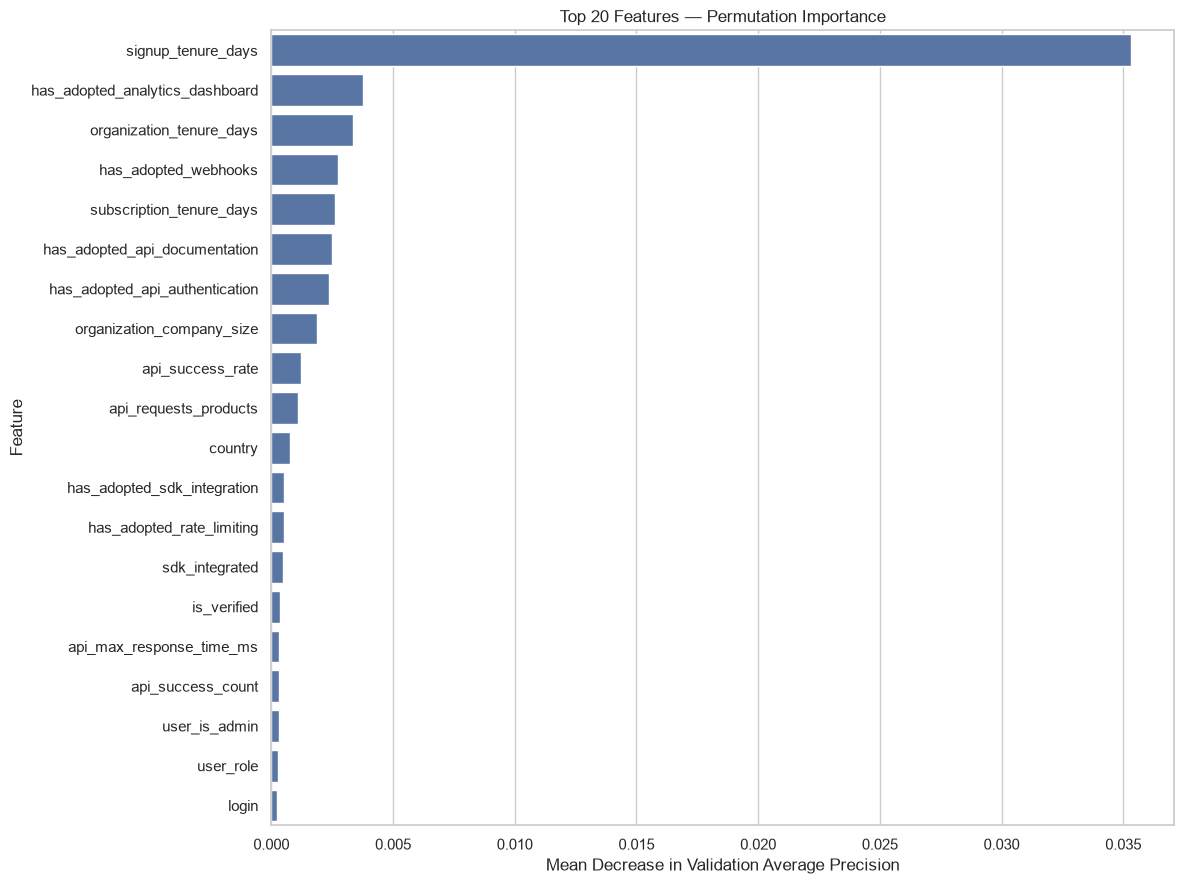

In [15]:
top_20_permutation = permutation_importance_df.head(20).copy()

plt.figure(figsize=(12, 9))

sns.barplot(
    data=top_20_permutation,
    x="Importance_Mean",
    y="Feature"
)

plt.title("Top 20 Features — Permutation Importance")
plt.xlabel("Mean Decrease in Validation Average Precision")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### Save permutation importance results

In [16]:
# Save permutation importance results
permutation_file = (
    output_dir / "random_forest_permutation_importance.csv"
)

permutation_importance_df.to_csv(
    permutation_file,
    index=False
)

print("Permutation importance saved successfully.")
print("File:", permutation_file.resolve())
print("Total features saved:", len(permutation_importance_df))

Permutation importance saved successfully.
File: C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\notebooks\models\interpretation\random_forest_permutation_importance.csv
Total features saved: 50


### Compare both importance methods

In [19]:
# Prepare comparison table
importance_comparison = feature_importance_df[
    ["Feature", "Importance"]
].merge(
    permutation_importance_df[
        ["Feature", "Importance_Mean", "Importance_Std"]
    ],
    on="Feature",
    how="inner"
)

# Add rankings
importance_comparison["Impurity_Rank"] = (
    importance_comparison["Importance"]
    .rank(ascending=False, method="min")
)

importance_comparison["Permutation_Rank"] = (
    importance_comparison["Importance_Mean"]
    .rank(ascending=False, method="min")
)

# Sort by permutation importance
importance_comparison = importance_comparison.sort_values(
    "Permutation_Rank"
).reset_index(drop=True)

display(importance_comparison.head(20).round(6))

,Feature,Importance,Importance_Mean,Importance_Std,Impurity_Rank,Permutation_Rank


### Correct the comparison table

In [21]:
# Recreate comparison table
importance_comparison = feature_importance_df[
    ["Feature", "Importance"]
].merge(
    permutation_importance_df[
        ["Feature", "Importance_Mean", "Importance_Std"]
    ],
    on="Feature",
    how="inner"
)

# Calculate rankings
importance_comparison["Impurity_Rank"] = (
    importance_comparison["Importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

importance_comparison["Permutation_Rank"] = (
    importance_comparison["Importance_Mean"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Sort by permutation rank
importance_comparison = importance_comparison.sort_values(
    by="Permutation_Rank"
).reset_index(drop=True)

# Display comparison
display(importance_comparison.head(20).round(6))

,Feature,Importance,Importance_Mean,Importance_Std,Impurity_Rank,Permutation_Rank


### Fix feature names and compare both methods

In [22]:
# Get original numerical and categorical feature names
original_features = numerical_features + categorical_features

# Map transformed features back to original features
def get_original_feature(transformed_feature):
    # Numerical features
    if transformed_feature.startswith("numerical__"):
        return transformed_feature.replace("numerical__", "", 1)

    # Categorical one-hot encoded features
    if transformed_feature.startswith("categorical__"):
        encoded_name = transformed_feature.replace(
            "categorical__", "", 1
        )

        matching_features = [
            col for col in categorical_features
            if encoded_name.startswith(col + "_")
        ]

        if matching_features:
            return max(matching_features, key=len)

    return transformed_feature


# Create a copy of impurity importance
impurity_df = feature_importance_df.copy()

impurity_df["Original_Feature"] = impurity_df["Feature"].apply(
    get_original_feature
)

# Aggregate one-hot encoded importance by original feature
impurity_grouped = (
    impurity_df.groupby("Original_Feature", as_index=False)
    ["Importance"].sum()
)

impurity_grouped = impurity_grouped.rename(
    columns={"Original_Feature": "Feature"}
)

# Merge with permutation importance
importance_comparison = impurity_grouped.merge(
    permutation_importance_df,
    on="Feature",
    how="inner"
)

# Calculate rankings
importance_comparison["Impurity_Rank"] = (
    importance_comparison["Importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

importance_comparison["Permutation_Rank"] = (
    importance_comparison["Importance_Mean"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Sort by permutation importance
importance_comparison = importance_comparison.sort_values(
    "Permutation_Rank"
).reset_index(drop=True)

print("Comparison rows:", len(importance_comparison))

display(importance_comparison.head(20).round(6))

Comparison rows: 50


,Feature,Importance,Importance_Mean,Importance_Std,Impurity_Rank,Permutation_Rank
0,signup_tenure_days,0.294306,0.035317,0.002760,1,1
1,has_adopted_analytics_dashboard,0.010406,0.003745,0.001882,18,2
2,organization_tenure_days,0.180498,0.003355,0.001603,2,3
3,has_adopted_webhooks,0.009305,0.002754,0.001372,23,4
4,subscription_tenure_days,0.100127,0.002602,0.001969,3,5
5,has_adopted_api_documentation,0.005682,0.002482,0.001493,32,6
6,has_adopted_api_authentication,0.009380,0.002356,0.001344,21,7
7,organization_company_size,0.007612,0.001863,0.000979,27,8
8,api_success_rate,0.015976,0.001233,0.000581,11,9
9,api_requests_products,0.004527,0.001076,0.000491,33,10


### Save the comparison table

In [23]:
comparison_file = (
    output_dir / "random_forest_importance_comparison.csv"
)

importance_comparison.to_csv(
    comparison_file,
    index=False
)

print("Importance comparison saved successfully.")
print("File:", comparison_file.resolve())
print("Total features:", len(importance_comparison))

Importance comparison saved successfully.
File: C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\notebooks\models\interpretation\random_forest_importance_comparison.csv
Total features: 50


### Identify consistently important features

In [24]:
consistent_features = importance_comparison[
    (importance_comparison["Impurity_Rank"] <= 10) &
    (importance_comparison["Permutation_Rank"] <= 10)
].copy()

print("Consistently important features:")
display(consistent_features.round(6))

Consistently important features:


,Feature,Importance,Importance_Mean,Importance_Std,Impurity_Rank,Permutation_Rank
0,signup_tenure_days,0.294306,0.035317,0.002760,1,1
2,organization_tenure_days,0.180498,0.003355,0.001603,2,3
4,subscription_tenure_days,0.100127,0.002602,0.001969,3,5


### Save the consistent features

In [25]:
consistent_file = (
    output_dir / "random_forest_consistent_features.csv"
)

consistent_features.to_csv(
    consistent_file,
    index=False
)

print("Consistent features saved successfully.")
print("File:", consistent_file.resolve())
print("Number of consistent features:", len(consistent_features))

Consistent features saved successfully.
File: C:\Users\User\Documents\AI-Feature-Adoption-Churn-Analytics\python\notebooks\models\interpretation\random_forest_consistent_features.csv
Number of consistent features: 3
